## Transfer Learning

In this section, we adopt a common compromise of [strategy A and strategy B](#strategies): freeze the `stem`, `layer1`, `layer2`, and `layer3`, and train only `layer4` and the new `fc`. This preserves most of the pre-trained features while allowing the high-level features to adapt to CIFAR-10.


In [16]:
import copy
import random
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset, Subset

import matplotlib.pyplot as plt
import torchvision
from torchvision import datasets, transforms
from torchvision.models import resnet18, ResNet18_Weights

### Guide

- **GOAL**

1. Explain **Pre-trained Model(预训练模型)** and **Transfer Learning(迁移学习)**

2. Differentiate **Feature Extractor(固定特征提取器)** and **Fine-tuning(微调)**

3. Substitute `fc` layer of ResNet

4. Control training parameters with `requires_grade`, and understand `train/eval` of `BatchNorm`

### Two common Transfer Learning strategies     <a id="strategies"></a>

#### Strategy A — CNN as a fixed feature extractor（固定特征提取器）

**Core idea**
- Load a pre-trained CNN.
- Freeze the parameters of the backbone.
- Replace the final classification layer.
- Train only the new classification head.

**For ResNet-18**

```text
Input
  │
  ▼
Pre-trained ResNet-18 backbone (冻结)   Note: backbone(骨干网络)
  │
  ▼
New Fully Connected Layer (训练)
  │
  ▼
10-class logits
```

> Here, the **backbone** refers to **the main network responsible for extracting visual features**, and `fc` is the original final fully-connected classification layer of ResNet-18.

#### Strategy B — Fine-tuning（微调）

**Core idea**
- Load the same pre-trained CNN as in Strategy A.
- Replace the final classification layer.
- Unfreeze a subset of the backbone layers.
- Continue training these layers on the target dataset.

#### Comparsion

| Aspect | Fixed feature extractor | Fine-tuning |
| --- | --- | --- |
| Pre-trained backbone params | All frozen | Partially unfrozen |
| New `fc` | Trained | Trained |
| Trainable parameters | Fewer | More |
| Training cost | Usually lower | Usually higher |
| When to use | Limited data; a quick, simple baseline | The target task differs from the pre-training task, so high-level features need adaptation |


> **Important:** Fine-tuning does **not** mean unfreezing the entire network. You can unfreeze only the last stage, or progressively unfreeze more layers.

## Set device and experiment configuration

In [47]:
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED) # for `torch.rand(3)`

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

batch_size = 32
EPOCHS_HEAD = 2
EPOCHS_FINETUNE = 2

# None means use the full DataLoader.
MAX_TRAIN_BATCHES = 20
MAX_EVAL_BATCHES = 10
TEST_EVAL_SAMPLES = 320

num_classes = 10

device: cpu


## Prepare CIFAR-10

the original size of CIFAR-10 is 32×32, and the standard inference preprocessing for an ImageNet-pretrained ResNet-18 resizes images to 224×224. So we resize/crop the CIFAR-10 image to 224×224.

In [18]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

train_transform=transforms.Compose([
    transforms.Resize(256),  # Important : `.Resize(256)` keeps the aspect ratio(纵横比) and scale the shorter edge to 256
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN,IMAGENET_STD)
])

eval_transform=transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN,IMAGENET_STD)
])


In [19]:
# Create train / validation / test splits
train_dataset=datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)

eval_dataset=datasets.CIFAR10(    # validation set(eval set/dev set) for observing training results, comparing schemes and selecting models
    root="./data",
    train=True,
    download=True,
    transform=eval_transform
)

test_dataset=datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=eval_transform
)

# split training data and eval data
generator=torch.Generator().manual_seed(SEED)
#`.Generator()` is a random number generate object
indices=torch.randperm(len(train_dataset),generator=generator).tolist()
#`.randperm()` means "Random Permutation(随即排列/置换)"    `.randperm(n)` generates all integers from 0 to n-1 as Tensor and randomize them

train_indices=indices[:45000]
eval_indices=indices[45000:]

train_set=Subset(train_dataset,train_indices)   #`Subset()` creates a new sub-dataset from an existing dataset based on specified indices
# `Subset(dataset, index)` like `Subset(dataset, [0,2,5,...,48903])`
eval_set=Subset(eval_dataset,eval_indices)
#-----------------------------------

classes=train_dataset.classes

print("classes:", classes)
print("train samples:", len(train_set))
print("validation samples:", len(eval_set))
print("test samples:", len(test_dataset))

classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
train samples: 45000
validation samples: 5000
test samples: 10000


In [20]:
train_loader=DataLoader(
    train_set,
    batch_size=batch_size,
    shuffle=True,
    #num_workers=0,
    pin_memory=torch.cuda.is_available()    # Important : pin the loader to memory(CUDA memory), and we must use `to(device)` while training
)

eval_loader=DataLoader(
    eval_set,
    batch_size=batch_size,
    shuffle=False,
    #num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader=DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    #num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# Use a fixed random subset for the quick comparison
test_generator=torch.Generator().manual_seed(SEED + 1)  # `manual_seed()` is a `method descriptor`
test_eval_indices=torch.randperm(len(test_dataset),generator=generator)[:TEST_EVAL_SAMPLES].tolist()

test_eval_set=Subset(test_dataset,test_eval_indices)
test_eval_loader=DataLoader(
    test_eval_set,
    batch_size=batch_size,
    shuffle=False,
    #num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("quick test eval set:",len(test_eval_set))
images, labels=next(iter(train_loader))
print("images shape:", images.shape)
print("labels shape:", labels.shape)

quick test eval set: 320
images shape: torch.Size([32, 3, 224, 224])
labels shape: torch.Size([32])


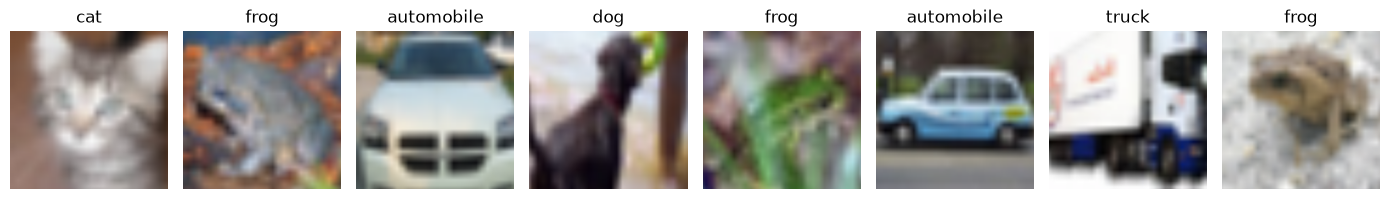

In [21]:
# Visualize a batch
def show_image(images,labels,class_names,n=8):
    mean=torch.tensor(IMAGENET_MEAN).view(3,1,1)
    std=torch.tensor(IMAGENET_STD).view(3,1,1)

    n=min(n,len(images))
    plt.figure(figsize=(14,3))

    for i in range(n):
        image=(images[i].cpu() * std+mean).clamp(0,1)
        plt.subplot(1,n,i+1)
        plt.imshow(image.permute(1,2,0))
        plt.title(class_names[labels[i]])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

show_image(images,labels,classes)

## Load a pre-trained ResNet-18

In [22]:
# download model weights from PyTorch ResNet18
torch.hub.set_dir("/data/zyhwork/ML/neural_network/Transfer_Learning")   # set downloading direction
# another way: `os.environ["TORCH_HOME"] = "/data/zyhwork/ML/neural_network/Transfer_Learning"`

weights=ResNet18_Weights.DEFAULT    # using default training weights from PyTorch official
model=resnet18(weights=weights)

```python
from ResNet.ResNet import resnet18

# download model weights from my own ResNet
model=resnet18(weights=None)

state_dict=torch.load(
    "/data/zyhwork/ML/neural_network/ResNet/resnet18_cifar10.pth",
    map_location="device",
    weights_only=True
)

model.load_state_dict(state_dict)   # model.load_state_dict(state_dict, strict=False)
model=model.to(device)
```
> **Important** : the **model architecure** and **weights** must be compatible

Otherwise, it will raise Error:`RuntimeError: Error(s) in loading state_dict`

Reason:

- Missing keys：模型需要某些参数，但权重文件中没有。

- Unexpected keys：权重文件中存在模型不需要的参数。

- Size mismatch：对应层的参数 shape 不一样。

In [23]:
preprocess_from_weights=weights.transforms()
print("recommended inference preprocessing",preprocess_from_weights)
print(model.__class__.__name__)
print("original fc:",model.fc)
print("fc input features:",model.fc.in_features)

recommended inference preprocessing ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
ResNet
original fc: Linear(in_features=512, out_features=1000, bias=True)
fc input features: 512


In [24]:
num_features=model.fc.in_features
model.fc=nn.Linear(num_features,num_classes)    # the class of CIFAR-10 is 10, but the original ResNet is for ImageNet

model=model.to(device)

example_images=torch.randn(4,3,224,224).to(device)
example_logits=model(example_images)

print("input shape:", example_images.shape)
print("output shape:",example_logits.shape)
print("new fc:",model.fc)

input shape: torch.Size([4, 3, 224, 224])
output shape: torch.Size([4, 10])
new fc: Linear(in_features=512, out_features=10, bias=True)


## Define training and evaluation functions

1. `optimizer.zero_grad()`: clear up the gradients of the late iteration.

2. `logits=model(feature)`: forward propagation, get the original output.

3. `loss=loss_fn(logits,labels)`: calculate the loss.

4. `loss.backward()`: backpropagation for calculating the gradients.

5. `optimizer.step()`: upgrade the parameters according to gradients.

This time we add a `training_mode`:

- `"head"`: freeze the `backbone`; keep only `fc` in `train mode`.

- `"layer4"`: freeze `stem` and `layer1`–`layer3`; keep only `layer4` and `fc` in `train mode`.

- `"all"`: put the entire model in `train mode`.

Because `train mode` / `eval mode` also governs `BatchNorm`, this flag controls its running behavior as well: frozen modules stay in `eval mode` and reuse the accumulated `running_mean` / `running_var`, while unfrozen modules in `train mode` keep updating those statistics from the current mini-batch.

In [25]:
def set_training_mode(model,training_mode):
    model.eval()

    if training_mode=="head":
        # Keep the entire backbone(including BN) in eval mode.
        model.fc.train()

    elif training_mode=="layer4":
        # Keep the frozen early backbone in eval mode.
        model.layer4.train()    # Partial Fine-tuning(部分微调)
        model.fc.train()

    elif training_mode=="all":
        model.train()           # Full Fine-tuning(完全微调)

    else:
        raise ValueError

def train_one_epoch(
        model,
        loader,
        loss_fn,
        optimizer,
        device,
        training_mode="all",
        max_batches=None
):
    set_training_mode(model,training_mode)

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for batch_idx, (images, labels) in enumerate(loader):   # `.enumerate()` gets index and value
            if max_batches is not None and batch_idx >= max_batches:
                 break
            
            images=images.to(device,non_blocking=True)
            labels=labels.to(device,non_blocking=True)
        #`non_blocking=True` allows PyTorch to use asynchronous(异同步) method for data transmission
        # `pin_memory=True` CPU to GPU, if the source data is in pinned memory(), asynchronous transfer is usually easier to achieve.

            optimizer.zero_grad(set_to_none=True)   # `set_to_none=True` can reduce the memory cost
            # `set_to_none=True` sets the gradient of model parameters to None instead of setting the gradient to 0

            logits=model(images)
            loss=loss_fn(logits, labels)

            loss.backward()
            optimizer.step()

            batch_size=labels.size(0)   # get the size of dim=0 of the Tensor labels
            total_loss+=loss.item()*batch_size
            total_correct+=(logits.argmax(dim=1)==labels).sum().item()
            total_samples+=batch_size

    if total_samples==0:
        raise RuntimeError

    return total_loss/total_samples, total_correct/total_samples

@torch.no_grad()
def evaluate(
    model,
    loader,
    loss_fn,
    device,
    max_batches=None
):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for batch_idx, (images, labels) in enumerate(loader):   # `.enumerate()` gets index and value
            if max_batches is not None and batch_idx >= max_batches:
                 break
            images=images.to(device,non_blocking=True)
            labels=labels.to(device,non_blocking=True)

            logits=model(images)
            loss=loss_fn(logits, labels)

            batch_size=labels.size(0)   # get the size of dim=0 of the Tensor labels
            total_loss+=loss.item()*batch_size
            total_correct+=(logits.argmax(dim=1)==labels).sum().item()
            total_samples+=batch_size

    if total_samples==0:
        raise RuntimeError

    return total_loss/total_samples, total_correct/total_samples

## Define a reusable fit function

We use `validation accuracy` to save the best-performing parameters within the current experiment.

**Note:** by default we set `MAX_TRAIN_BATCHES` and `MAX_EVAL_BATCHES` cap the training and validation batch amounts, so the default output is a quick experimental result, **not** the final `benchmark` of a full `CIFAR-10` training run.

In [34]:
def fit_model(
    model,
    train_loader,
    eval_loader,
    loss_fn,
    optimizer,
    device,
    epochs,
    training_mode,
    max_train_batches=None,
    max_eval_batches=None
):
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=epochs)
    history={"train_loss":[], "train_acc":[], "val_loss":[], "val_acc":[]}
    best_val_acc=-1.0
    best_state=copy.deepcopy(model.state_dict())  # equivalent to creating an independent copy(副本) of the model state

    for epoch in range(1,epochs+1):
        train_loss, train_acc=train_one_epoch(
            model,
            train_loader,
            loss_fn,
            optimizer,
            device,
            training_mode=training_mode,
            max_batches=max_train_batches
        )

        val_loss, val_acc=evaluate(
            model,
            eval_loader,
            loss_fn,
            device,
            max_batches=max_eval_batches
        )

        scheduler.step()

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc=val_acc
            best_state=copy.deepcopy(model.state_dict())

        current_lr=optimizer.param_groups[0]["lr"]  # Important : `param_groups` is a list which stores all the Parameter Groups of optimizer

        print(
            f"Epoch [{epoch:02d}/{epochs}] "
            f"train_loss={train_loss:.4f}, "
            f"train_acc={train_acc:.2%} | "
            f"val_loss={val_loss:.4f}, "
            f"val_acc={val_acc:.2%} | "
            f"lr={current_lr:.6f}"
        )

    model.load_state_dict(best_state)
    #Important : Reload the best model state into the current model, restoring the model Parameters and Buffers
    print(f"Best validation accuracy:{best_val_acc:.2%}")

    return model, history

## Strategy A - Fixed feature extractor

In [27]:
model_head=resnet18(weights=weights)

# 1. Freeze every existing parameter.
for parameter in model_head.parameters():
    parameter.requires_grad=False   # Important : `requires_grad` decides whether this parameter need 

# 2. Replace the classifier AFTER freezing the original model.
num_features=model_head.fc.in_features
model_head.fc=nn.Linear(num_features,num_classes).to(device)

# Only the new classifier should be trainable.
trainable_params=sum(
    parameter.numel() for parameter in model_head.parameters() if parameter.requires_grad
)
total_params=sum(
    parameter.numel() for paramter in model_head.parameters()
)

print(f"trainable parameters:{trainable_params:,}") # `,` is thousands separator(千位分隔符)
print(f"total parameters:{total_params:,}")
print(f"trainable ratio:{trainable_params/total_params:.2%}")

trainable parameters:5,130
total parameters:62,000
trainable ratio:8.27%


In [28]:
# Check which layers are trainable
for name, parameter in model_head.named_parameters():   # `.named_parameters()` returns all "learnable parameters" of the model with an iterator
    if name.startswith("layer4") or name.startswith("fc"):  # `object.startswitch("str")` is a method for str. It checks if the `objct` starts with `str`
        print(f"{name:25s} requires_grad={parameter.requires_grad}")

layer4.0.conv1.weight     requires_grad=False
layer4.0.bn1.weight       requires_grad=False
layer4.0.bn1.bias         requires_grad=False
layer4.0.conv2.weight     requires_grad=False
layer4.0.bn2.weight       requires_grad=False
layer4.0.bn2.bias         requires_grad=False
layer4.0.downsample.0.weight requires_grad=False
layer4.0.downsample.1.weight requires_grad=False
layer4.0.downsample.1.bias requires_grad=False
layer4.1.conv1.weight     requires_grad=False
layer4.1.bn1.weight       requires_grad=False
layer4.1.bn1.bias         requires_grad=False
layer4.1.conv2.weight     requires_grad=False
layer4.1.bn2.weight       requires_grad=False
layer4.1.bn2.bias         requires_grad=False
fc.weight                 requires_grad=True
fc.bias                   requires_grad=True


Two distinct mechanisms are often confused when working with **BatchNorm**:

1. `requires_grad=False` freezes the learnable parameters — for **BatchNorm**, its `weight` and `bias`.
2. `model.eval()` switches **BatchNorm** to the accumulated running statistics (`running_mean` / `running_var`) and stops updating them from the current mini-batch.

So freezing the parameters is **not** equivalent to freezing **BatchNorm**'s running statistics.

In a fixed-feature-extractor setup, we want the pretrained backbone to remain truly fixed. During training we therefore put the whole model in `eval mode` and set only the `fc` layer back to `train mode`. The ResNet-18 backbone has no `Dropout`, so this keeps the **BatchNorm** statistics stable throughout training.

### Only the new classifier

In [35]:
# train `fc` only
loss_fn=nn.CrossEntropyLoss()

optimizer_head=torch.optim.AdamW(
    model_head.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

model_head, history_head=fit_model(
    model=model_head,
    train_loader=train_loader,
    eval_loader=eval_loader,
    loss_fn=loss_fn,
    optimizer=optimizer_head,
    device=device,
    epochs=EPOCHS_HEAD,
    training_mode="head",
    max_train_batches=MAX_TRAIN_BATCHES,
    max_eval_batches=MAX_EVAL_BATCHES
)

Epoch [01/2] train_loss=0.9047, train_acc=71.56% | val_loss=0.8694, val_acc=70.62% | lr=0.000500
Epoch [02/2] train_loss=0.8208, train_acc=77.66% | val_loss=0.8113, val_acc=73.44% | lr=0.000000
Best validation accuracy:73.44%


### Visualize the training curves

Inspect `train` / `validation` `loss` and `accuracy`:

- If `train accuracy` rises and `validation accuracy` rises too, the new classification head is learning the target task;
- If `train accuracy` keeps rising but `validation accuracy` stops improving, overfitting may occur;
- If both are low, it may also be due to too few training epochs, limited data, unsuitable hyperparameters, or a large gap between the target data and the pretrained features.

Do not look only at the numbers from a single `epoch`; judge from the curves as much as possible.

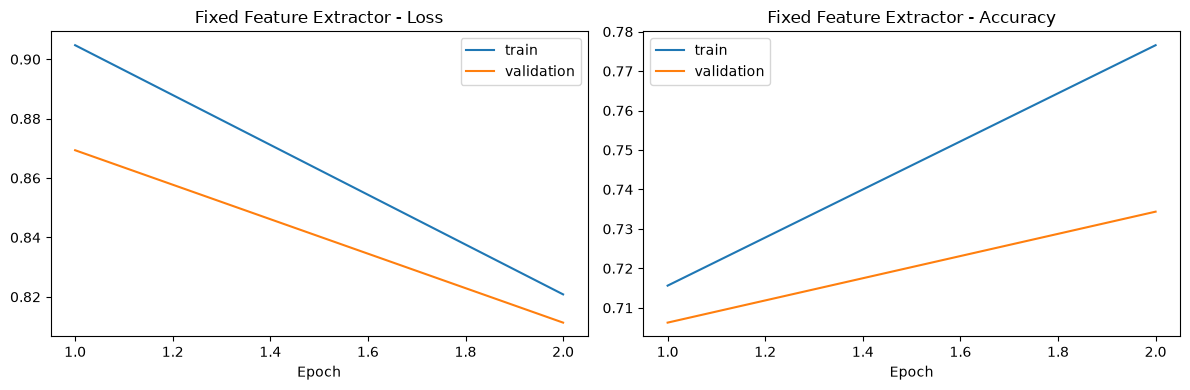

In [ ]:
def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4)) # `fig` is the whole canva, and `axes` are subfigs

    axes[0].plot(epochs, history["train_loss"], label="train")
    axes[0].plot(epochs, history["val_loss"], label="validation")
    axes[0].set_title(f"{title} - Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()    # legend(图例)

    axes[1].plot(epochs, history["train_acc"], label="train")
    axes[1].plot(epochs, history["val_acc"], label="validation")
    axes[1].set_title(f"{title} - Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_history(history_head, "Fixed Feature Extractor")

## Strategy B - Fine-tuning

In [38]:
# load a fresh pre-trained model
model_ft=resnet18(weights=weights)

num_features=model_ft.fc.in_features
model_ft.fc=nn.Linear(num_features,num_classes)

# Freeze `stem` and `layer1-3`
for parameter in model_ft.conv1.parameters():
    parameter.requires_grad=False

for parameter in model_ft.bn1.parameters():
    parameter.requires_grad=False

for parameter in model_ft.layer1.parameters():
    parameter.requires_grad=False

for parameter in model_ft.layer2.parameters():
    parameter.requires_grad=False

for parameter in model_ft.layer3.parameters():
    parameter.requires_grad=False

# Unfreeze `layer4` and `fc`
for parameter in model_ft.layer4.parameters():
    parameter.requires_grad=True

for parameter in model_ft.fc.parameters():
    parameter.requires_grad=True

model_ft=model_ft.to(device)

trainable_params_ft=sum(
    parameter.numel()
    for parameter in model_ft.parameters() if parameter.requires_grad # equivalent`parameter.requires_grad==True`
)
total_params_ft=sum(
    parameter.numel()
    for parameter in model_ft.parameters()
)

print(f"trainable parameters: {trainable_params_ft:,}")
print(f"total parameters:     {total_params_ft:,}")
print(f"trainable ratio:      {trainable_params_ft / total_params_ft:.2%}")

trainable parameters: 8,398,858
total parameters:     11,181,642
trainable ratio:      75.11%


In [ ]:
# Using `Parameter Groups` to set different learning rate  for different part
# Important : this is "Differential Learning Rates(差分学习率)"
optimizer_ft=torch.optim.AdamW(
    [
    {"params":model_ft.layer4.parameters(),"lr":5e-4},
    {"params":model_ft.fc.parameters(),"lr":5e-4}
    ],
    weight_decay=2e-4   # Important : we can also set different `weight_decay` for different `paramter group`
)

for group_idx, group in enumerate(optimizer_ft.param_groups):
    print(
        f"group {group_idx}: "
        f"lr={group["lr"]}, "
        f"number of tensors={len(group["params"])}"
    )

group 0: lr=0.0005, number of tensors=15
group 1: lr=0.0005, number of tensors=2


### Train the partially unfrozen model

- Set the whole model `model.eval()`, so the frozen part don't update **running statics**

- Then set `layer4` and `fc` as `.train()`, the BatchNorm of `layer4` can still update **running statics** with its mini-batch.

Epoch [01/2] train_loss=0.7388, train_acc=75.62% | val_loss=0.7037, val_acc=75.62% | lr=0.000250
Epoch [02/2] train_loss=0.6149, train_acc=79.53% | val_loss=0.5711, val_acc=78.12% | lr=0.000000
Best validation accuracy:78.12%


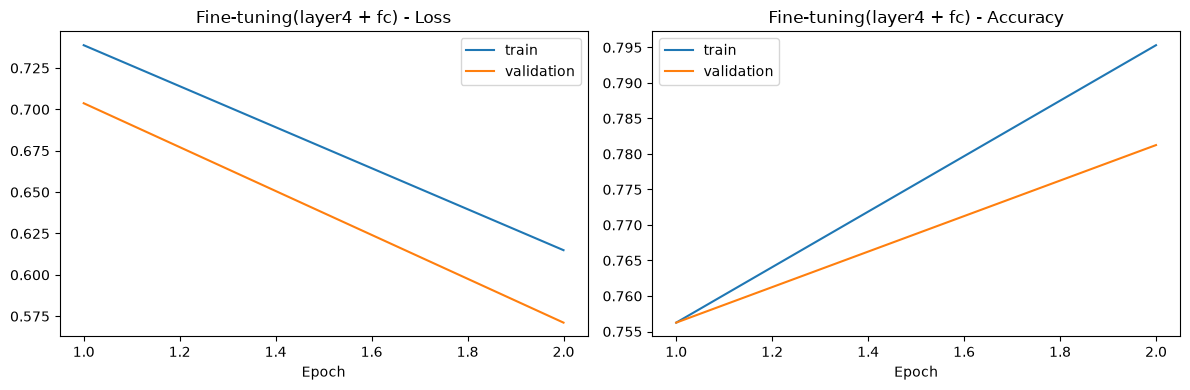

In [51]:
model_ft, history_ft = fit_model(
    model=model_ft,
    train_loader=train_loader,
    eval_loader=eval_loader,
    loss_fn=loss_fn,
    optimizer=optimizer_ft,
    device=device,
    epochs=EPOCHS_FINETUNE,
    training_mode="layer4",
    max_train_batches=MAX_TRAIN_BATCHES,
    max_eval_batches=MAX_EVAL_BATCHES
)

plot_history(history_ft,"Fine-tuning(layer4 + fc)")

## Compare the two strategies

We can compare the two strategies on the `validation set`.

| Strategy | Backbone | Classifier | Expected cost |
| --- | --- | --- | --- |
| `Fixed feature extractor` | `fully frozen` | `trained` | Lower |
| `Fine-tuning` | `layer4` unfrozen, rest frozen | `trained` | Higher |

`Fine-tuning` is not guaranteed to be better every time. With limited data, unfreezing too many layers may instead lead to overfitting; if the target task is very close to the pretraining task, the `Fixed feature extractor` may already be good enough.

In [52]:
head_best_val_acc = max(history_head["val_acc"])
ft_best_val_acc = max(history_ft["val_acc"])

print(f"Fixed feature extractor best val acc: {head_best_val_acc:.2%}")
print(f"Fine-tuning best val acc:              {ft_best_val_acc:.2%}")
print(f"Trainable params (head only):          {trainable_params:,}")
print(f"Trainable params (layer4 + fc):        {trainable_params_ft:,}")

Fixed feature extractor best val acc: 73.44%
Fine-tuning best val acc:              78.12%
Trainable params (head only):          5,130
Trainable params (layer4 + fc):        8,398,858


## Evaluate on the test set

In [54]:
test_loss_head, test_acc_head = evaluate(
    model_head,
    test_eval_loader,   # `test_loader` is the full dataset
    loss_fn,
    device
)

test_loss_ft, test_acc_ft = evaluate(
    model_ft,
    test_eval_loader,   # `test_loader`
    loss_fn,
    device
)

print("Fixed feature extractor:")
print(f"test_loss={test_loss_head:.4f}, test_acc={test_acc_head:.2%}")

print("\nFine-tuning:")
print(f"test_loss={test_loss_ft:.4f}, test_acc={test_acc_ft:.2%}")

Fixed feature extractor:
test_loss=0.8152, test_acc=80.31%

Fine-tuning:
test_loss=0.5327, test_acc=81.25%


### Inspect predictions

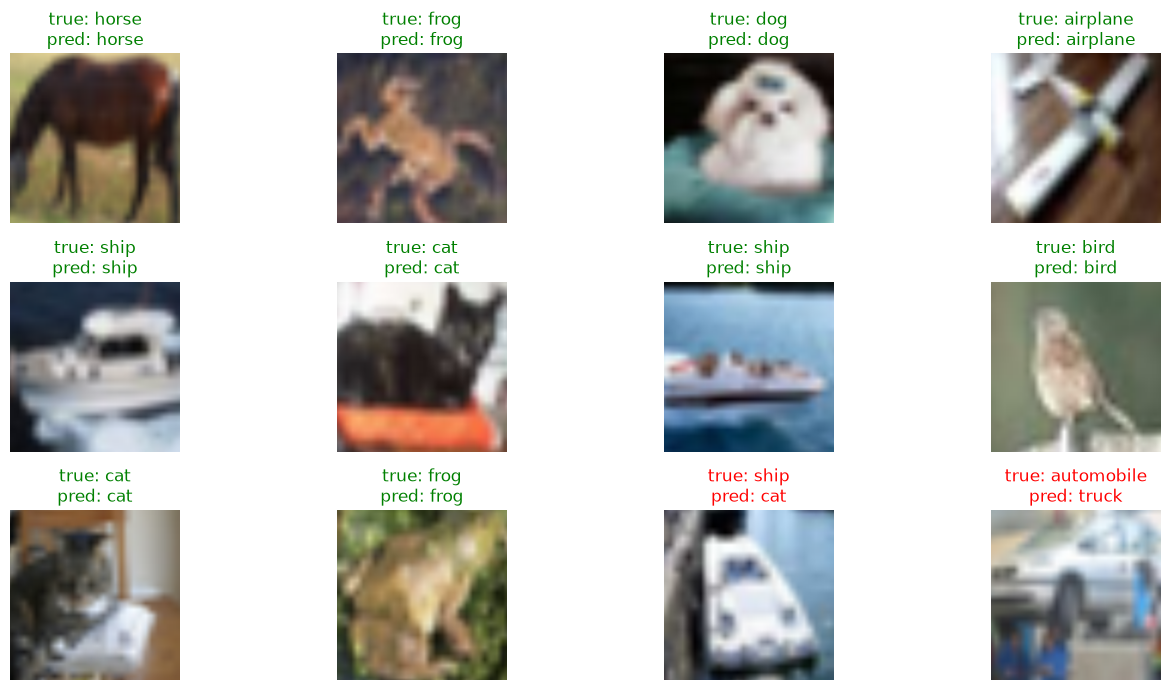

In [ ]:
@torch.no_grad()
def show_predictions(model, loader, class_names, device, n=12):
    model.eval()

    images, labels = next(iter(loader))
    images_device = images[:n].to(device)
    logits = model(images_device)
    predictions = logits.argmax(dim=1).cpu()

    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

    n = min(n, len(images))
    plt.figure(figsize=(14, 7))

    for i in range(n):
        image = (images[i].cpu() * std + mean).clamp(0, 1)

        true_name = class_names[labels[i]]
        pred_name = class_names[predictions[i]]
        title_color = "green" if true_name == pred_name else "red"

        plt.subplot(3, 4, i + 1)
        plt.imshow(image.permute(1, 2, 0))
        plt.title(
            f"true: {true_name}\npred: {pred_name}",
            color=title_color
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

show_predictions(model_ft, test_eval_loader, classes, device)
#show_predictions(model_ft, test_loader, classes, device)

## Save and reload the fine-tuning model

In [58]:
checkpoint_path=Path("transfer_resnet18_cifar10.pth")

checkpoint={
    "model_state_dict":model_ft.state_dict(),
    "class_names":classes,
    "num_classes":num_classes,
    "architecture":"resnet18",
    "pretrained_weights":"ResNet18_Weights.DEFAULT",
    "fine_tuned_layers":["layer4","fc"]
}

torch.save(checkpoint, checkpoint_path)
print(checkpoint_path.resolve())

/data/zyhwork/ML/neural_network/Transfer_Learning/transfer_resnet18_cifar10.pth


In [60]:
# Recreate the same architecture before loading its `state_dict`
loaded_model=resnet18(weights=None)
loaded_model.fc=nn.Linear(loaded_model.fc.in_features,num_classes)

saved_checkpoint=torch.load(checkpoint_path,map_location=device)
loaded_model.load_state_dict(saved_checkpoint["model_state_dict"])

loaded_model=loaded_model.to(device)
loaded_classes=saved_checkpoint["class_names"]

loaded_model.eval()

print(loaded_classes)

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## References

[PyTorch Tutorials — Transfer Learning for Computer Vision](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)

[TorchVision — resnet18 model and pretrained weights](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)

[TorchVision — Models and pre-trained weights](https://docs.pytorch.org/vision/stable/models.html)